# Phase 5 — Explainable fuzzy classifier

In this part of Assignment 2, I use geometric measurements of facial expressions to build an interpretable fuzzy classifier for the seven KDEF emotions. The notebook covers T11 (facial feature extraction) and T12 (fuzzy classification). The experiment uses frontal photographs, dlib's 68-point landmark predictor and the subject-independent split provided by the group.

The geometric feature extraction produced seven measurements for all 980 frontal photographs, with no reported detection failures. The training-only feature analysis and internal validation split are also complete. The fuzzy models, held-out test evaluation and rule interpretation have not been run yet.

## 1. Environment and local paths

This section defines the local paths for the original KDEF photographs, the pretrained landmark predictor and the team's subject-split file. The dataset is stored outside the Git repository, while `KDEF_ROOT` allows the same notebook to run with a different folder layout. The supplied split contains 56 training and 14 testing subjects, with no overlap.

In [1]:
from pathlib import Path
import os
import pickle

import cv2
import dlib
import numpy as np
import pandas as pd

cwd = Path.cwd().resolve()
ROOT = next(
    (
        path
        for path in (cwd, *cwd.parents)
        if (path / "auxFiles/kdef_subject_split.pkl").is_file()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Repository root not found")

KDEF_ROOT = Path(
    os.getenv("KDEF_ROOT", str(ROOT.parent / "KDEF"))
).expanduser().resolve()
SPLIT_FILE = ROOT / "auxFiles/kdef_subject_split.pkl"
PREDICTOR_FILE = (
    ROOT
    / "models/faceAndLandmarkModels"
    / "shape_predictor_68_face_landmarks.dat"
)
DATA_OUT = ROOT / "data/fuzzy"
OUT = ROOT / "outputs/fuzzy"

for path in (KDEF_ROOT, SPLIT_FILE, PREDICTOR_FILE):
    if not path.exists():
        raise FileNotFoundError(path)

for folder in (DATA_OUT, OUT):
    folder.mkdir(parents=True, exist_ok=True)

with SPLIT_FILE.open("rb") as file:
    subject_split = pickle.load(file)  # Trusted team repository file.

train_subjects = set(subject_split["train_subjects"])
test_subjects = set(subject_split["test_subjects"])

assert train_subjects.isdisjoint(test_subjects), "Subject leakage detected"
assert (len(train_subjects), len(test_subjects)) == (56, 14)

print(f"KDEF: {KDEF_ROOT}")
print(f"Subjects: {len(train_subjects)} train / {len(test_subjects)} test")
print(f"NumPy: {np.__version__} | dlib: {dlib.__version__}")

KDEF: /Users/henriquedasilvacouto/workspace/TUe-Master_AI_and_ES/Masters-database/5ARE0_2026-GS1/Assignment_2/KDEF
Subjects: 56 train / 14 test
NumPy: 1.24.4 | dlib: 19.24.2


## 2. Read KDEF metadata

KDEF filenames contain the subject identity, acquisition session, emotion and viewing angle. I use the same emotion codes and known filename corrections as the group's existing loader, selecting only the frontal (`S`) photographs. Both acquisition sessions are associated with the same subject ID. The resulting metadata contains 980 frontal images from 70 individuals, equally distributed across the seven emotions, with no unrecognized filenames.

In [2]:
EMOTIONS = {
    "AF": "afraid",
    "AN": "angry",
    "DI": "disgust",
    "HA": "happy",
    "NE": "neutral",
    "SA": "sad",
    "SU": "surprise",
}
OVERRIDES = {"AF31V": "AF31SAHL", "AM31H": "AM31SUHR"}
VALID_POSES = {"FL", "HL", "S", "HR", "FR"}

rows = []
rejected = []
for path in sorted(KDEF_ROOT.rglob("*")):
    if not path.is_file() or path.suffix.lower() not in (".jpg", ".jpeg"):
        continue

    stem = OVERRIDES.get(path.stem.upper(), path.stem.upper())
    if len(stem) < 7:
        rejected.append((str(path), "short filename"))
        continue

    emotion_code = stem[4:6]
    pose_code = stem[6:]
    if emotion_code not in EMOTIONS or pose_code not in VALID_POSES:
        rejected.append((str(path), f"unrecognized emotion/pose: {stem}"))
        continue
    if pose_code != "S":
        continue

    rows.append({
        "path": str(path),
        "relative_path": str(path.relative_to(KDEF_ROOT)),
        "image_name": path.name,
        "subject": stem[1:4],
        "acquisition": stem[0],
        "emotion": EMOTIONS[emotion_code],
        "pose": "straight",
    })

meta = pd.DataFrame(rows)
assert len(meta) == 980
assert meta["subject"].nunique() == 70
assert meta["emotion"].value_counts().eq(140).all()

print(f"Frontal images: {len(meta)} | Subjects: {meta['subject'].nunique()}")
print(f"Unrecognized filenames: {len(rejected)}")
meta.head()

Frontal images: 980 | Subjects: 70
Unrecognized filenames: 0


,path,relative_path,image_name,subject,acquisition,emotion,pose
0,/Users/henriquedasilvacouto/workspace/TUe-Mast...,AF01/AF01AFS.JPG,AF01AFS.JPG,F01,A,afraid,straight
1,/Users/henriquedasilvacouto/workspace/TUe-Mast...,AF01/AF01ANS.JPG,AF01ANS.JPG,F01,A,angry,straight
2,/Users/henriquedasilvacouto/workspace/TUe-Mast...,AF01/AF01DIS.JPG,AF01DIS.JPG,F01,A,disgust,straight
3,/Users/henriquedasilvacouto/workspace/TUe-Mast...,AF01/AF01HAS.JPG,AF01HAS.JPG,F01,A,happy,straight
4,/Users/henriquedasilvacouto/workspace/TUe-Mast...,AF01/AF01NES.JPG,AF01NES.JPG,F01,A,neutral,straight


## 3. Apply the predefined train/test split

The existing subject split assigns each person's photographs to either training or testing, independently of acquisition session. This gives 784 training images from 56 subjects and 196 test images from 14 subjects. Each emotion has 112 training images and 28 test images, so the partitions remain balanced without splitting photographs from the same individual across sets.

In [3]:
if not meta["subject"].isin(train_subjects | test_subjects).all():
    raise ValueError("KDEF contains subjects outside the supplied split")

meta["split"] = np.where(
    meta["subject"].isin(train_subjects), "train", "test"
)
print(meta.groupby(["split", "emotion"]).size().unstack(fill_value=0))
print(meta.groupby("split")["subject"].nunique())

emotion  afraid  angry  disgust  happy  neutral  sad  surprise
split                                                         
test         28     28       28     28       28   28        28
train       112    112      112    112      112  112       112
split
test     14
train    56
Name: subject, dtype: int64


## 4. Define seven geometric features

I represent each face using seven measurements derived from the 68 dlib landmarks: mouth width, mouth opening, left and right eye opening, eyebrow height, mouth width-to-height ratio and mouth-corner asymmetry. Distances are expressed relative to face or eye width to reduce sensitivity to image scale. `smile_ratio` is a geometric aspect ratio rather than a direct measurement of happiness, and its value can be sensitive to small mouth heights.

The formulas use zero-based landmark indices, following the point reference below.

Points were mapped according to this reference:

<img src="../auxFiles/face-landmarks-detection-opencv-with-python-points.jpg" width="400">

In [4]:
from numpy.linalg import norm

FEATURE_COLS = [
    "mouth_width",
    "mouth_opening",
    "left_eye_opening",
    "right_eye_opening",
    "eyebrow_height",
    "smile_ratio",
    "mouth_corner_asymmetry",
]


def landmark_distance(points, index_a, index_b):
    """Calculate the Euclidean distance between two facial landmarks."""
    return float(norm(points[index_a] - points[index_b]))


def geometric_features(points):
    """Extract seven ratios from the 68 facial landmark coordinates."""
    eps = 1e-6
    face_width = max(landmark_distance(points, 0, 16), eps)
    mouth_width = landmark_distance(points, 48, 54)
    mouth_height = landmark_distance(points, 51, 57)

    return {
        "mouth_width": mouth_width / face_width,
        "mouth_opening": landmark_distance(points, 62, 66) / face_width,
        "left_eye_opening": (
            landmark_distance(points, 37, 41)
            + landmark_distance(points, 38, 40)
        ) / (2 * max(landmark_distance(points, 36, 39), eps)),
        "right_eye_opening": (
            landmark_distance(points, 43, 47)
            + landmark_distance(points, 44, 46)
        ) / (2 * max(landmark_distance(points, 42, 45), eps)),
        "eyebrow_height": (
            landmark_distance(points, 19, 37)
            + landmark_distance(points, 24, 44)
        ) / (2 * face_width),
        "smile_ratio": mouth_width / max(mouth_height, eps),
        "mouth_corner_asymmetry": abs(
            float(points[48, 1] - points[54, 1])
        ) / face_width,
    }

## 5. Detect the face and its landmarks

Landmarks are extracted from the original-resolution photographs rather than the 48 × 48 FER-style images, preserving more detail for geometric measurements. The dlib face detector identifies the face region and the pretrained shape predictor returns 68 `(x, y)` coordinates. If more than one face is detected, the largest detected region is selected.

In [5]:
face_detector = dlib.get_frontal_face_detector()
landmark_predictor = dlib.shape_predictor(str(PREDICTOR_FILE))


def detect_landmarks(path):
    """Read an image and return the image and its 68 landmarks."""
    bgr = cv2.imread(str(path))
    if bgr is None:
        raise ValueError(f"Image unreadable: {path}")

    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    faces = face_detector(gray, 1)
    if not faces:
        raise ValueError(f"No face detected: {path}")

    face = max(faces, key=lambda rect: rect.width() * rect.height())
    shape = landmark_predictor(gray, face)
    points = np.array(
        [(point.x, point.y) for point in shape.parts()], dtype=float
    )
    if points.shape != (68, 2):
        raise ValueError(f"Unexpected landmark array: {points.shape}")

    return bgr, points

## 6. Inspect landmark positions

Six photographs from the training subjects were sampled with a fixed random seed and displayed with their 68 landmarks overlaid. The overlays provide a visual check that the points follow the expected facial structure, particularly around the eyes, eyebrows and mouth. This is a qualitative check on a small sample rather than proof that every detected landmark is accurate.

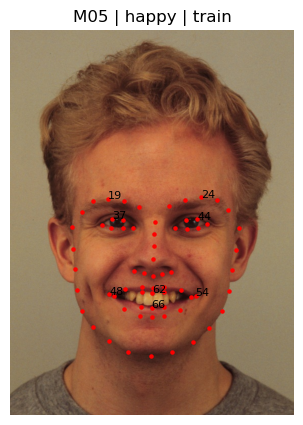

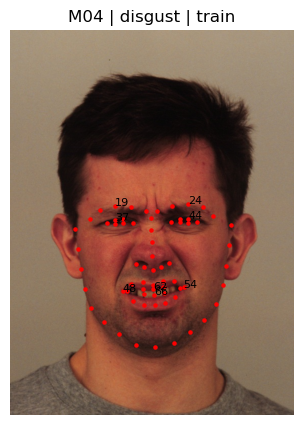

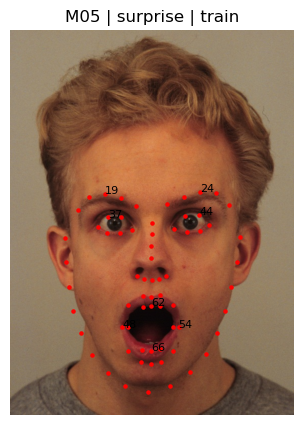

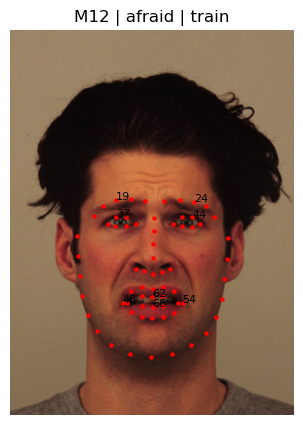

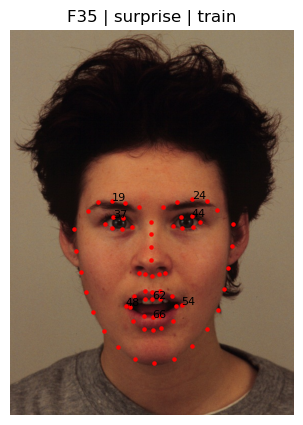

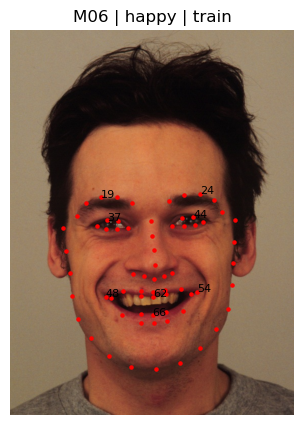

In [6]:
import matplotlib.pyplot as plt

sample = meta.loc[meta["split"] == "train"].sample(6, random_state=42)
for _, record in sample.iterrows():
    try:
        image, points = detect_landmarks(record["path"])
        rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(5, 5))
        plt.imshow(rgb)
        plt.scatter(points[:, 0], points[:, 1], s=5, c="red")
        for index in (19, 24, 37, 44, 48, 54, 62, 66):
            plt.annotate(str(index), tuple(points[index]), fontsize=8)
        plt.title(
            f"{record['subject']} | {record['emotion']} | {record['split']}"
        )
        plt.axis("off")
        plt.show()
    except (ValueError, cv2.error) as exc:
        print(f"Failed: {record['path']} — {exc}")

## 7. Extract the geometric features

The landmark detector and feature formulas were applied to all 980 frontal photographs. All images produced finite values for the seven measurements, with zero recorded extraction failures. The resulting DataFrame contains the features together with emotion labels and subject/split metadata. The extracted features and failure log are saved as CSV files; exported image paths are relative to the KDEF folder so they do not depend on my local directory structure.

In [7]:
features = []
failures = []

for _, record in meta.iterrows():
    try:
        _, points = detect_landmarks(record["path"])
        measurements = geometric_features(points)
        features.append({**record.to_dict(), **measurements})
    except (ValueError, RuntimeError, OSError, cv2.error) as exc:
        failures.append({**record.to_dict(), "error": str(exc)})

feature_df = pd.DataFrame(features)
failure_df = pd.DataFrame(failures, columns=[*meta.columns, "error"])

assert not feature_df.empty, "No features could be extracted"
assert np.isfinite(feature_df[FEATURE_COLS].to_numpy()).all()

feature_df.drop(columns="path").to_csv(
    DATA_OUT / "kdef_geometric_features.csv", index=False
)
failure_df.drop(columns="path", errors="ignore").to_csv(
    OUT / "landmark_failures.csv", index=False
)

print(f"Success: {len(feature_df)} | Failures: {len(failure_df)}")
print(feature_df.groupby(["split", "emotion"]).size().unstack(fill_value=0))

Success: 980 | Failures: 0
emotion  afraid  angry  disgust  happy  neutral  sad  surprise
split                                                         
test         28     28       28     28       28   28        28
train       112    112      112    112      112  112       112


## 8. Review feature quality

The feature analysis uses the 784 training images only, keeping the 196 test images out of feature selection. For each emotion, I calculated the count, mean, standard deviation, median and range of the seven measurements and saved the summary as `feature_summary.csv`. The averages show clear differences in some measurements: for example, happy has a mean mouth width of 0.497 compared with 0.371 for neutral, while surprise has a mean mouth opening of 0.105 compared with 0.006 for neutral. These are descriptive differences, not evidence that a feature can classify an emotion on its own.

In [8]:
# Work with training subjects only.
train_features = feature_df[feature_df["split"] == "train"].copy()
test_features = feature_df[feature_df["split"] == "test"]

# Check feature values and subject independence.
assert np.isfinite(feature_df[FEATURE_COLS].to_numpy()).all()
assert set(train_features["subject"]).isdisjoint(test_features["subject"])

# Summarize each feature for every emotion.
feature_summary = (
    train_features.melt(
        id_vars="emotion",
        value_vars=FEATURE_COLS,
        var_name="feature",
        value_name="value"
    )
    .groupby(["feature", "emotion"])["value"]
    .agg(["count", "mean", "std", "median", "min", "max"])
    .round(4)
    .reset_index()
)

feature_summary.to_csv(OUT / "feature_summary.csv", index=False)

print(f"Training images: {len(train_features)}")
print(f"Test images: {len(test_features)}")
print(f"Detection failures: {len(failure_df)}")

display(feature_summary.pivot(
    index="feature",
    columns="emotion",
    values="mean"
).round(3))


Training images: 784
Test images: 196
Detection failures: 0


emotion,afraid,angry,disgust,happy,neutral,sad,surprise
feature,,,,,,,
eyebrow_height,0.122,0.080,0.096,0.130,0.124,0.123,0.156
left_eye_opening,0.378,0.292,0.226,0.265,0.339,0.301,0.428
mouth_corner_asymmetry,0.010,0.011,0.012,0.013,0.009,0.011,0.009
mouth_opening,0.066,0.029,0.052,0.078,0.006,0.009,0.105
mouth_width,0.378,0.357,0.377,0.497,0.371,0.382,0.339
right_eye_opening,0.378,0.290,0.225,0.266,0.338,0.302,0.430
smile_ratio,2.189,3.181,2.521,3.097,3.440,3.515,1.576


### 8.1. Outliers, correlations and distributions

We used the interquartile range (IQR) to flag potentially unusual training measurements and calculated Pearson correlations between the seven features. Mouth width has the most IQR outliers (58), which may reflect genuine facial expressions rather than invalid measurements. Left and right eye opening are almost perfectly correlated (0.99), and `smile_ratio` is negatively correlated with mouth opening (−0.74), partly because the two features share related mouth-height measurements. Boxplots for four features show how their distributions overlap across emotions.

Potential outliers by feature:
mouth_width               58
mouth_corner_asymmetry    12
mouth_opening             10
eyebrow_height             8
smile_ratio                8
left_eye_opening           2
right_eye_opening          0
dtype: int64

Feature correlations:


,mouth_width,mouth_opening,left_eye_opening,right_eye_opening,eyebrow_height,smile_ratio,mouth_corner_asymmetry
mouth_width,1.00,0.12,-0.41,-0.41,0.07,0.28,0.18
mouth_opening,0.12,1.00,0.19,0.20,0.29,-0.74,0.05
left_eye_opening,-0.41,0.19,1.00,0.99,0.37,-0.34,-0.17
right_eye_opening,-0.41,0.20,0.99,1.00,0.38,-0.35,-0.17
eyebrow_height,0.07,0.29,0.37,0.38,1.00,-0.26,-0.00
smile_ratio,0.28,-0.74,-0.34,-0.35,-0.26,1.00,0.02
mouth_corner_asymmetry,0.18,0.05,-0.17,-0.17,-0.00,0.02,1.00


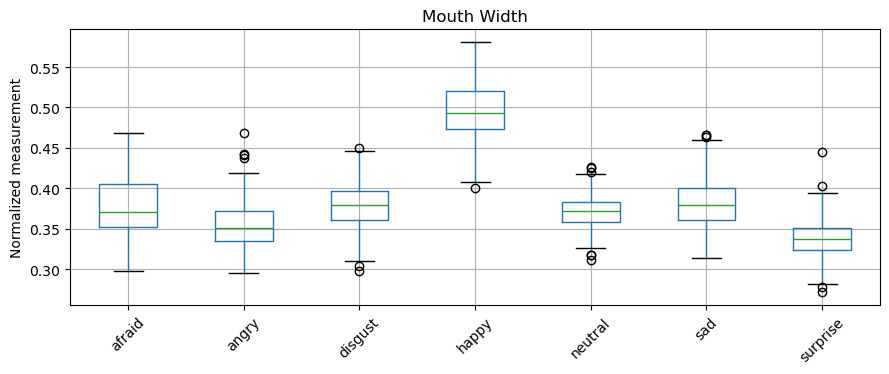

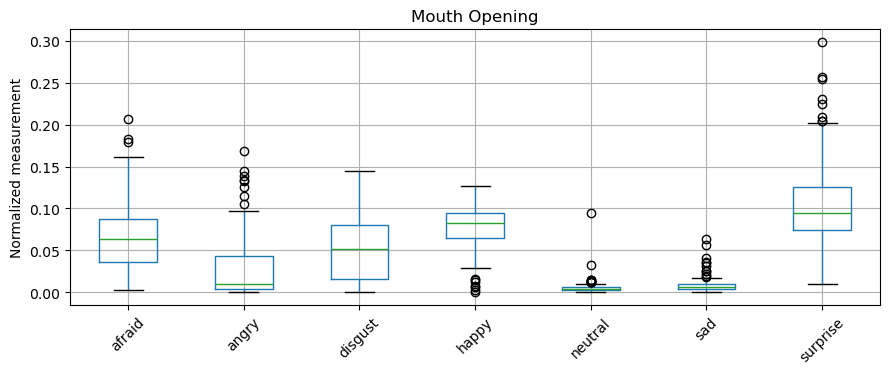

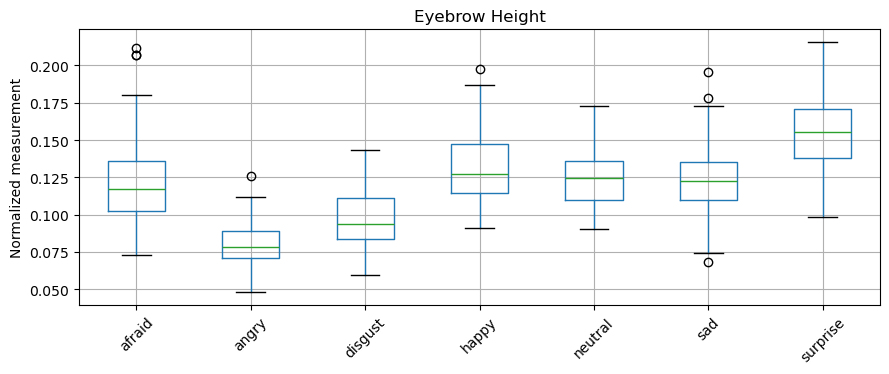

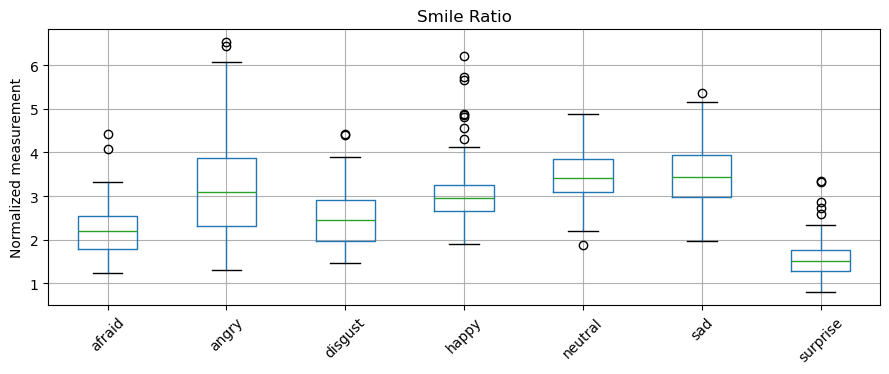

In [9]:

# Identify possible outliers using the IQR method.
q1 = train_features[FEATURE_COLS].quantile(0.25)
q3 = train_features[FEATURE_COLS].quantile(0.75)
iqr = q3 - q1

outliers = (
    train_features[FEATURE_COLS].lt(q1 - 1.5 * iqr)
    | train_features[FEATURE_COLS].gt(q3 + 1.5 * iqr)
)

print("Potential outliers by feature:")
print(outliers.sum().sort_values(ascending=False))

# Check correlations between geometric measurements.
print("\nFeature correlations:")
display(train_features[FEATURE_COLS].corr().round(2))

# Compare distributions across emotions.
features_to_plot = [
    "mouth_width",
    "mouth_opening",
    "eyebrow_height",
    "smile_ratio"
]

for feature in features_to_plot:
    fig, ax = plt.subplots(figsize=(9, 4))
    train_features.boxplot(
        column=feature,
        by="emotion",
        ax=ax,
        rot=45
    )
    fig.suptitle("")
    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel("Normalized measurement")
    plt.tight_layout()
    plt.show()


### 8.2. Interpretation of the training features

The training distributions suggest that mouth width, mouth opening and eyebrow height may carry useful information for emotion recognition. Happy expressions tend to have wider mouths, surprise tends to have more mouth opening and higher eyebrows, and angry expressions tend to have lower eyebrows. However, the distributions overlap, and the strong correlation between left and right eye opening suggests that some measurements are redundant. I kept all seven features for the first fuzzy-model experiment so that any later feature reduction can be assessed on the validation subjects.

| Feature | Observation from training data | Interpretation |
|---|---|---|
| Mouth width | Happy has the highest median | A useful candidate for recognising happy expressions |
| Mouth opening | Surprise, happy and afraid show higher values | Potentially informative, with overlap between emotions |
| Eyebrow height | Surprise is highest and angry is lowest | Consistent with expected brow movement |
| `smile_ratio` | Surprise is low; neutral and sad are relatively high | A mouth aspect ratio, not a direct smile measurement |
| Eye opening | Left and right measurements correlate at 0.99 | Likely redundant information |

## 9. Prepare an internal validation split

Model configuration needs to be evaluated without using the 14 subjects reserved for final testing. I therefore used `GroupShuffleSplit` to divide the original 56 training subjects into 44 subjects for model fitting (616 images) and 12 subjects for validation (168 images). Each of the seven emotions remains equally represented, with 88 fitting and 24 validation images per class. `MinMaxScaler` was fitted only on the internal training group and then applied to the validation group, preventing validation or test measurements from influencing the scaling parameters.

In [10]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import MinMaxScaler

# Split by subject rather than by image.
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

fit_idx, val_idx = next(
    splitter.split(train_features, groups=train_features["subject"])
)

fit_df = train_features.iloc[fit_idx].copy()
val_df = train_features.iloc[val_idx].copy()

# Verify that the partitions contain different subjects.
assert set(fit_df["subject"]).isdisjoint(val_df["subject"])
assert set(fit_df["subject"]).isdisjoint(test_features["subject"])
assert set(val_df["subject"]).isdisjoint(test_features["subject"])

# Normalize using the internal training data only.
scaler = MinMaxScaler()

X_fit = scaler.fit_transform(fit_df[FEATURE_COLS])
X_val = scaler.transform(val_df[FEATURE_COLS])

y_fit = fit_df["emotion"].to_numpy()
y_val = val_df["emotion"].to_numpy()

print("Training subjects:", fit_df["subject"].nunique())
print("Validation subjects:", val_df["subject"].nunique())
print("Training images:", len(X_fit))
print("Validation images:", len(X_val))

print("\nTraining class distribution:")
print(fit_df["emotion"].value_counts().sort_index())

print("\nValidation class distribution:")
print(val_df["emotion"].value_counts().sort_index())


Training subjects: 44
Validation subjects: 12
Training images: 616
Validation images: 168

Training class distribution:
afraid      88
angry       88
disgust     88
happy       88
neutral     88
sad         88
surprise    88
Name: emotion, dtype: int64

Validation class distribution:
afraid      24
angry       24
disgust     24
happy       24
neutral     24
sad         24
surprise    24
Name: emotion, dtype: int64


## 10. Test PyFUME with one emotion

PyFUME estimates Takagi–Sugeno fuzzy systems with numerical outputs. To adapt this approach for emotion classification, I started with a binary model that assigns a target of 1 to happy expressions and 0 to all other emotions. The seven normalized geometric features are used as inputs, with two fuzzy clusters selected for this initial experiment. The model is evaluated on the previously separated validation subjects to verify that inference produces finite numerical scores. I also inspect PyFUME's internal data partition and generated rules before extending the method to all seven emotions.

In [14]:
from pyfume import pyFUME
from contextlib import contextmanager


@contextmanager
def working_directory(directory):
    """Temporarily change the working directory."""
    previous_directory = Path.cwd()
    directory.mkdir(parents=True, exist_ok=True)

    try:
        os.chdir(directory)
        yield
    finally:
        os.chdir(previous_directory)


# Binary target: happy (1) versus other emotions (0).
target_emotion = "happy"

train_table = pd.DataFrame(X_fit, columns=FEATURE_COLS)
train_table["OUTPUT"] = (
    fit_df["emotion"].to_numpy() == target_emotion
).astype(float)


# Keep PyFUME-generated files separate for each emotion.
work_dir = OUT / "pyfume_work" / target_emotion

# Fit the fuzzy model using all available training observations.
np.random.seed(42)

with working_directory(work_dir):
    happy_model = pyFUME(
        dataframe=train_table,
        nr_clus=2,
        data_split_method="no_split",
        setnes_threshold=1.0,
        merge_threshold=1.0
    )

print("PyFUME files:", [p.name for p in work_dir.iterdir()])


# Predict scores for the validation subjects.
happy_scores = np.asarray(
    happy_model.predict_label(X_val), dtype=float
).ravel()

assert len(happy_scores) == len(X_val)
assert np.isfinite(happy_scores).all()

print("Validation samples:", len(happy_scores))
print("Score range:", happy_scores.min(), happy_scores.max())
print("First 10 scores:", happy_scores[:10].round(3))

# Check the internal PyFUME data partition.

internal_train, _ = happy_model.get_data(data_set="train")

print("Available training images:", len(train_table))
print("Images used by PyFUME:", len(internal_train))
print("External validation images:", len(X_val))

assert len(internal_train) == len(train_table), (
    "PyFUME did not use all training observations"
)


# Compare validation scores by target class.
score_summary = pd.DataFrame({
    "is_happy": val_df["emotion"].to_numpy() == target_emotion,
    "score": happy_scores
})

display(
    score_summary.groupby("is_happy")["score"]
    .describe()
    .round(3)
)

# Keep the generated rules for later interpretation.
generated_code = work_dir / "Simpful_code.py"

if generated_code.is_file():
    print("Fuzzy rules saved:", generated_code)
else:
    print("Generated rules not found")

 * Detected 0 categorical variables.
['mouth_width' 'mouth_opening' 'left_eye_opening' 'right_eye_opening'
 'eyebrow_height' 'smile_ratio' 'mouth_corner_asymmetry']
PyFUME files: ['__new_dataset.csv', 'Simpful_code.py']
Validation samples: 168
Score range: -0.3476397264136786 1.1457686524407045
First 10 scores: [-0.209 -0.207  0.373  0.87  -0.032  0.018  0.048  0.213  0.513  0.276]
Available training images: 616
Images used by PyFUME: 616
External validation images: 168


,count,mean,std,min,25%,50%,75%,max
is_happy,,,,,,,,
False,144.0,-0.002,0.165,-0.348,-0.102,-0.022,0.056,0.537
True,24.0,0.692,0.183,0.463,0.573,0.625,0.779,1.146


Fuzzy rules saved: /Users/henriquedasilvacouto/workspace/TUe-Master_AI_and_ES/Masters-database/5ARE0_2026-GS1/Assignment_2/ml-emotionalrecognition/outputs/fuzzy/pyfume_work/happy/Simpful_code.py


### 10.1) Conclusion

The initial PyFUME model successfully learned a numerical distinction between happy and non-happy expressions. On the 168 validation images, happy expressions received a mean score of 0.699, compared with -0.001 for the remaining emotions. The model generated two Takagi–Sugeno fuzzy rules using the seven geometric features. Disabling rule simplification resolved the earlier model-construction error.

PyFUME also applied an additional internal 75/25 split to the 616 input observations, resulting in 462 fitting and 154 internal testing samples. This behaviour needs to be considered when configuring the complete seven-emotion classifier. The model outputs are treated as numerical scores rather than calibrated probabilities.

## 11. Compare seven fuzzy emotion models

**Planned — not yet evaluated.** The proposed classifier uses one binary-output fuzzy model for each of the seven emotions. Each model estimates a score for its own emotion and the highest score determines the predicted class. Two- and three-cluster configurations will be compared using the same subject-independent validation set, with attention to macro-F1, balanced accuracy and rule interpretability. The final choice will be based on validation results, not the held-out test subjects.

In [ ]:
# TODO: Train seven one-versus-rest systems on the fit subjects.
# TODO: Evaluate the same validation subjects for each cluster setting.
# TODO: Record metrics and inspect whether one model dominates.
# TODO: Choose the final configuration without using test subjects.

## 12. Refit and evaluate on held-out KDEF subjects

**Planned — not yet evaluated.** Once a configuration has been selected using the internal validation set, the scaler and fuzzy models will be refitted using all 56 original training subjects. The 14 held-out subjects will then be used for the final evaluation. Accuracy, balanced accuracy, macro-F1 and a confusion matrix will describe the classification results, alongside the number of landmark-detection failures. Each fitted emotion model's rule representation will be preserved separately.

In [ ]:
# TODO: Refit preprocessing and fuzzy models on all training subjects.
# TODO: Preserve each model's generated fuzzy-rule code after fitting.
# TODO: Predict test emotions with the chosen decision rule.
# TODO: Save test metrics and the confusion matrix.

## 13. Interpret the learned fuzzy rules

**Planned — no learned rules available yet.** A fuzzy classifier is useful for this assignment only if its rules can be related to facial geometry. The analysis will examine the actual membership functions, antecedents and numerical Takagi–Sugeno consequents, then compare a small number of learned patterns with expected facial expressions. Plausible and counterintuitive relationships will both be documented rather than replacing the model's output with hand-written rules.

In [ ]:
# TODO: Open the saved rule representation for each emotion.
# TODO: Record actual antecedents and consequents for selected rules.
# TODO: Identify plausible and unexpected patterns for the report.

## 14. Save and verify the fitted models

**Planned — not yet evaluated.** Reproducing a fuzzy prediction requires more than the trained models: the input feature order, scaling parameters, class order and model representations must also be preserved. The saved artifacts will be reloaded and checked against previously recorded predictions. Successful file creation alone will not be treated as proof that PyFUME models can be restored correctly.

In [ ]:
# TODO: Save the scaler, class names and seven trained models.
# TODO: Restart the kernel or use a fresh process to reload the files.
# TODO: Confirm that restored predictions match saved predictions.

## 15. Notes for the group report

**To be completed after model evaluation.** The Phase 5 report contribution will summarise the geometric feature definitions, subject-independent evaluation, selected fuzzy configuration, measured performance and examples of genuinely learned rules. It will also discuss feature overlap, correlated measurements, detection limitations and the interpretation of fuzzy output scores. The final report must include the assignment's AI-use disclosure.

In [ ]:
# TODO: List the completed figures, metrics and model files.
# TODO: Draft short report notes based on measured results only.
# TODO: Update T11/T12 evidence in workload.md after team agreement.